In [3]:
!pip -q install numpy pandas matplotlib pillow opencv-python torch torchvision scikit-learn scikit-image tqdm

In [2]:
import os, copy, subprocess, pathlib, json, pickle, glob, sys, time, warnings, shutil
from collections import defaultdict
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
REPO = pathlib.Path("sparsh")
if not REPO.exists():
    try:
        subprocess.run(["git", "clone", "https://github.com/facebookresearch/sparsh.git", str(REPO)], check=True)
    except Exception as e:
        print("Could not clone the repository (no internet?):", repr(e))
        print("If your GelSight .pkl files are already on disk, ignore this and set DATA_ROOT in step 4.")
print("Repository:", REPO.resolve(), "| exists:", REPO.exists())
print("GelSight download script exists:", (REPO/"scripts/download_gelsight_dataset.sh").exists())

Repository: /content/sparsh | exists: True
GelSight download script exists: True


In [4]:
script = REPO / "scripts/download_gelsight_dataset.sh"
print(script.read_text()[:12000] if script.exists() else "Script not available - place your .pkl files under DATA_ROOT manually.")

#!/bin/bash

# set path to the directory to donwload the dataset
path_dataset="/media/chiguera/GUM/datasets/"

mkdir -p $path_dataset/gelsight
cd $path_dataset/gelsight

# download object_folder dataset
echo "Downloading the backbone dataset gelsight/object_folder"
gdown https://drive.google.com/drive/folders/1kgKj3BhvSN8bF1hI2bjeqhcaCHyxJUss?usp=sharing --folder


# download touch_go dataset
echo "Downloading the backbone dataset gelsight/touch_go"
gdown https://drive.google.com/drive/folders/1Rpy9ZHCfJjwycj7TMuEbwwHEtH79ls8D?usp=sharing --folder

# extract files
cd ./touch_go
for i in */; do tar -xvf "${i%/}.tar.gz"; done
rm *.tar.gz

echo "Done!"



In [5]:
from pathlib import Path
from google.colab import drive

drive.mount("/content/drive")

DATA_ROOT = "/content/drive/MyDrive/datasets"

# Verify that Colab can see the .pkl files inside the shortcut
obj_path = Path(DATA_ROOT) / "gelsight" / "object_folder"
print("ObjectFolder .pkl files found:", len(list(obj_path.glob("*.pkl"))))



Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
ObjectFolder .pkl files found: 8


In [6]:
DATA_ROOT = pathlib.Path("datasets")        # change if you used another destination
search_roots = [DATA_ROOT, REPO, pathlib.Path(".")]
pkl_files = []
for root in search_roots:
    if root.exists():
        pkl_files.extend(root.glob("**/*.pkl"))
pkl_files = sorted(set(p.resolve() for p in pkl_files
                       if any(s in str(p).lower() for s in ("gelsight", "touch_go", "object_folder"))))
print("Found candidate pickle files:", len(pkl_files))
for p in pkl_files[:20]: print(p)
if not pkl_files:
    raise FileNotFoundError("No prepared GelSight pickle files found. Confirm the download destination / DATA_ROOT.")

def describe_tree(obj, path="root", depth=0, max_depth=4):
    if depth > max_depth: return
    if isinstance(obj, dict):
        for k, v in list(obj.items())[:40]: describe_tree(v, f"{path}.{k}", depth + 1, max_depth)
    elif isinstance(obj, (list, tuple)):
        print(path, type(obj).__name__, "len=", len(obj))
        if len(obj): describe_tree(obj[0], path + "[0]", depth + 1, max_depth)
    elif isinstance(obj, np.ndarray):
        print(path, "ndarray", obj.shape, obj.dtype)
    elif hasattr(obj, "shape") and hasattr(obj, "dtype"):
        print(path, type(obj).__name__, getattr(obj, "shape", None), getattr(obj, "dtype", None))
    else:
        print(path, type(obj).__name__)

with open(pkl_files[0], "rb") as f:
    sample_obj = pickle.load(f, encoding="latin1")
describe_tree(sample_obj)

Found candidate pickle files: 8
/content/drive/.shortcut-targets-by-id/1kgKj3BhvSN8bF1hI2bjeqhcaCHyxJUss/object_folder/001.pkl
/content/drive/.shortcut-targets-by-id/1kgKj3BhvSN8bF1hI2bjeqhcaCHyxJUss/object_folder/002.pkl
/content/drive/.shortcut-targets-by-id/1kgKj3BhvSN8bF1hI2bjeqhcaCHyxJUss/object_folder/011.pkl
/content/drive/.shortcut-targets-by-id/1kgKj3BhvSN8bF1hI2bjeqhcaCHyxJUss/object_folder/012.pkl
/content/drive/.shortcut-targets-by-id/1kgKj3BhvSN8bF1hI2bjeqhcaCHyxJUss/object_folder/021.pkl
/content/drive/.shortcut-targets-by-id/1kgKj3BhvSN8bF1hI2bjeqhcaCHyxJUss/object_folder/031.pkl
/content/drive/.shortcut-targets-by-id/1kgKj3BhvSN8bF1hI2bjeqhcaCHyxJUss/object_folder/041.pkl
/content/drive/.shortcut-targets-by-id/1kgKj3BhvSN8bF1hI2bjeqhcaCHyxJUss/object_folder/051.pkl
root list len= 12000
root[0] bytes


001.pkl image-like records: 300
002.pkl image-like records: 300
011.pkl image-like records: 300
012.pkl image-like records: 300
021.pkl image-like records: 300
031.pkl image-like records: 300
041.pkl image-like records: 300
051.pkl image-like records: 300
Total image-like records found: 2400


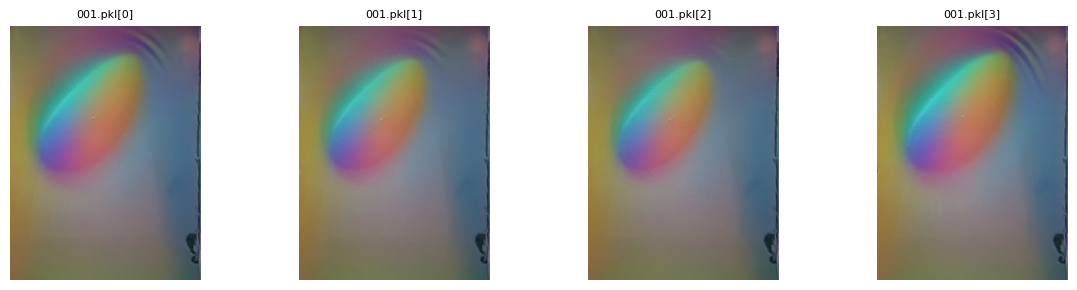

In [7]:
import io
import pickle
import matplotlib.pyplot as plt
import numpy as np
from PIL import Image


def _try_decode_image(obj):
  """Decodes PIL Images or raw JPEG/PNG bytes into an (H, W, 3) uint8 numpy array."""
  if isinstance(obj, Image.Image):
    return np.asarray(obj.convert("RGB"), dtype=np.uint8)
  if isinstance(obj, (bytes, bytearray, memoryview)):
    try:
      with Image.open(io.BytesIO(obj)) as im:
        return np.asarray(im.convert("RGB"), dtype=np.uint8)
    except Exception:
      return None
  return None


def collect_images(obj, found=None, path="root", max_per_pkl=300):
  if found is None:
    found = []
  if len(found) >= max_per_pkl:
    return found

  # 1. Check if obj is a PIL Image or encoded JPEG/PNG bytes
  decoded = _try_decode_image(obj)
  if decoded is not None:
    found.append((path, decoded))
    return found

  # 2. Traverse dictionaries
  if isinstance(obj, dict):
    for k, v in obj.items():
      if len(found) >= max_per_pkl:
        break
      collect_images(v, found, f"{path}.{k}", max_per_pkl)

  # 3. Traverse lists/tuples (now allowing bytes and PIL Images)
  elif isinstance(obj, (list, tuple)):
    if len(obj) and isinstance(
        obj[0],
        (dict, list, tuple, np.ndarray, bytes, bytearray, Image.Image),
    ):
      for i, v in enumerate(obj[:500]):
        if len(found) >= max_per_pkl:
          break
        collect_images(v, found, f"{path}[{i}]", max_per_pkl)

  # 4. Handle standard 3D/4D numpy arrays
  else:
    try:
      a = np.asarray(obj)
    except Exception:
      return found
    if a.ndim == 4:
      if a.shape[-1] in (3, 4):
        for i in range(min(len(a), max_per_pkl - len(found))):
          found.append((f"{path}[{i}]", a[i][..., :3]))
      elif a.shape[1] in (3, 4):
        for i in range(min(len(a), max_per_pkl - len(found))):
          found.append((f"{path}[{i}]", np.moveaxis(a[i][:3], 0, -1)))
    elif (
        a.ndim == 3
        and (a.shape[-1] in (3, 4) or a.shape[0] in (3, 4))
        and min(a.shape[:2]) >= 32
    ):
      img = (
          np.moveaxis(a, 0, -1)
          if a.shape[0] in (3, 4) and a.shape[-1] not in (3, 4)
          else a
      )
      found.append((path, img[..., :3]))
  return found


MAX_PICKLES_TO_SCAN = 12
image_records = []
for fp in pkl_files[:MAX_PICKLES_TO_SCAN]:
  try:
    with open(fp, "rb") as f:
      obj = pickle.load(f, encoding="latin1")
    rec = collect_images(obj, path=str(fp), max_per_pkl=300)
    image_records.extend(rec)
    print(f"{fp.name} image-like records: {len(rec)}")
  except Exception as e:
    print("Could not parse", fp, repr(e))

print("Total image-like records found:", len(image_records))
if not image_records:
  raise RuntimeError(
      "No RGB tactile arrays auto-detected. Adapt collect_images() to the tree"
      " printed in step 4."
  )

fig, axs = plt.subplots(1, min(4, len(image_records)), figsize=(12, 3))
axs = np.atleast_1d(axs)
for ax, (name, img) in zip(axs, image_records[:4]):
  ax.imshow(np.asarray(img).astype(np.uint8))
  ax.set_title(name.split("/")[-1][:24], fontsize=8)
  ax.axis("off")
plt.tight_layout()
plt.show()


In [8]:
import torch, torch.nn as nn, torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from sklearn.model_selection import GroupShuffleSplit

SEED = 17; np.random.seed(SEED); torch.manual_seed(SEED)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu"); device = DEVICE
print("Device:", DEVICE)

MAX_FRAMES = 12000
IMAGE_SIZE = 64
BLOCK = 150
STIFFNESS_BY_FILE = {}      # e.g. {"object_a.pkl": 2.0}; default 1.0 (unknown)
rng = np.random.default_rng(SEED)

n_all = len(image_records)
keep = np.sort(rng.choice(n_all, MAX_FRAMES, replace=False)) if n_all > MAX_FRAMES else np.arange(n_all)
image_records = [image_records[i] for i in keep]          # sorted -> frame order preserved

def prep_rgb(a, size=IMAGE_SIZE):
    a = np.asarray(a)
    if a.ndim != 3: raise ValueError(a.shape)
    if a.shape[0] in (3, 4) and a.shape[-1] not in (3, 4): a = np.moveaxis(a, 0, -1)
    a = a[..., :3]
    if a.dtype != np.uint8:
        if np.nanmax(a) <= 1.5: a = a * 255
        a = np.nan_to_num(a).clip(0, 255).astype(np.uint8)
    im = Image.fromarray(a).resize((size, size), Image.Resampling.BILINEAR)
    return np.asarray(im).transpose(2, 0, 1).astype(np.float32) / 255.

def file_of(name): return name.split(".pkl")[0] + ".pkl" if ".pkl" in name else name.split("[")[0]

X = np.stack([prep_rgb(a) for _, a in image_records])                 # [N,3,H,W]
files = np.array([file_of(n) for n, _ in image_records])
del image_records
uniq_files, file_id = np.unique(files, return_inverse=True)
pos = np.zeros(len(X), int); cnt = defaultdict(int)
for i, f in enumerate(file_id):
    pos[i] = cnt[f]; cnt[f] += 1
groups = files if len(uniq_files) >= 5 else np.array([f"{f}|{p // BLOCK}" for f, p in zip(files, pos)])
N = len(X)
print("Optical tensor:", X.shape, "range", float(X.min()), float(X.max()),
      "| recordings:", len(uniq_files), "| split groups:", len(np.unique(groups)))

# ---- per-recording reference + contact proxies
REF = np.stack([np.median(X[file_id == f], axis=0) for f in range(len(uniq_files))]).astype(np.float32)   # [F,3,H,W]
g = np.linspace(-0.5, 0.5, IMAGE_SIZE, dtype=np.float32)
UU, VV = np.meshgrid(g, g)                       # UU: x (columns), VV: y (rows)
F_raw = np.zeros(N, np.float32); cen = np.zeros((N, 2), np.float32)
for s in range(0, N, 512):
    sl = slice(s, s + 512)
    dev = np.abs(X[sl] - REF[file_id[sl]]).mean(1)                       # [b,H,W]
    F_raw[sl] = dev.mean((1, 2))
    w = np.clip(dev - np.median(dev.reshape(len(dev), -1), axis=1)[:, None, None], 0, None) ** 2
    sw = w.sum((1, 2)) + 1e-12
    cen[sl, 0] = (w * UU).sum((1, 2)) / sw
    cen[sl, 1] = (w * VV).sum((1, 2)) / sw
for f in range(len(uniq_files)):
    m = file_id == f
    F_raw[m] = np.clip(F_raw[m] - np.percentile(F_raw[m], 5), 0, None)
k_raw = np.array([STIFFNESS_BY_FILE.get(Path(u).name, 1.0) for u in uniq_files], np.float32)[file_id]

# ---- recording-grouped split: 20% test, then 20% of the rest validation
tv_idx, test_idx = next(GroupShuffleSplit(1, test_size=.20, random_state=SEED).split(np.arange(N), groups=groups))
tr_rel, va_rel = next(GroupShuffleSplit(1, test_size=.20, random_state=SEED + 1).split(tv_idx, groups=groups[tv_idx]))
train_idx, val_idx = tv_idx[tr_rel], tv_idx[va_rel]
print("train/val/test frames:", len(train_idx), len(val_idx), len(test_idx))

Device: cuda
Optical tensor: (2400, 3, 64, 64) range 0.019607843831181526 0.9215686321258545 | recordings: 8 | split groups: 8
train/val/test frames: 1200 600 600


In [16]:
# ---- re-split using only the recordings that are assigned to a shape (block-grouped so every shape appears in train/val/test)
SHAPES_BY_FILE = {"001.pkl": ["sphere", "foam_ellipsoid"], "002.pkl": ["sphere", "foam_ellipsoid"],
                  "021.pkl": ["cylinder"], "031.pkl": ["cylinder"]}
used_idx = np.where(np.array([Path(u).name in SHAPES_BY_FILE for u in uniq_files])[file_id])[0]
blk = np.array([f"{Path(uniq_files[f]).name}|{p // BLOCK}" for f, p in zip(file_id[used_idx], pos[used_idx])])   # same-name copies (e.g. the two 001.pkl) land in the same block
tv_rel, te_rel = next(GroupShuffleSplit(1, test_size=.20, random_state=SEED).split(used_idx, groups=blk))
tr_rel, va_rel = next(GroupShuffleSplit(1, test_size=.20, random_state=SEED + 1).split(tv_rel, groups=blk[tv_rel]))
train_idx, val_idx, test_idx = used_idx[tv_rel[tr_rel]], used_idx[tv_rel[va_rel]], used_idx[te_rel]
print("train/val/test frames (used recordings only):", len(train_idx), len(val_idx), len(test_idx))
assert len(train_idx) and len(val_idx) and len(test_idx), "empty split"

F_SCALE = float(np.percentile(F_raw[train_idx], 95)) + 1e-8
K_REF = float(k_raw[train_idx].mean()) + 1e-8
cond_all = np.stack([np.clip(F_raw / F_SCALE, 0, 2), np.clip(k_raw / K_REF, 0.25, 4)], 1).astype(np.float32)

SPHERE_R = 0.25; DELTA_SCALE = 0.08; DELTA_MAX = 0.12
BOUNDS_LO = (-1.0, -1.0, -0.4); BOUNDS_HI = (1.0, 1.0, 0.9)
SDF_CLAMP = 0.1; SURF_NOISE = 0.04; SURF_RMAX = 0.5
delta_all = np.clip(DELTA_SCALE * (cond_all[:, 0] / cond_all[:, 1]) ** (2 / 3), 0, DELTA_MAX).astype(np.float32)
print("force proxy (normalized) train mean %.3f | pseudo delta train mean %.3f max %.3f"
      % (cond_all[train_idx, 0].mean(), delta_all[train_idx].mean(), delta_all[train_idx].max()))

# ---- three indenter shapes (1 normalized unit = 20 cm, so SPHERE_R = 0.25 <-> 5 cm). All have their lowest point
# 0.25 below the centre, so rest_center() (centre height = SPHERE_R) is valid for every shape.
SHAPE_NAMES = ["sphere", "cylinder", "foam_ellipsoid"]          # shape id = index in this list
CYL_R, CYL_HALF_H = 0.15, 0.25                  # cylinder: height 10 cm (given); radius 3 cm (ASSUMPTION - not specified)
ELL_AXES = (0.30, 0.20, 0.25)                   # foam ellipsoid semi-axes 6 x 4 x 5 cm (ASSUMPTION - not specified)
# recording (file name) -> shape(s) it is used for. A recording may serve several shapes; unlisted recordings are not used.
SHAPES_BY_FILE = {"001.pkl": ["sphere", "foam_ellipsoid"], "002.pkl": ["sphere", "foam_ellipsoid"],
                  "021.pkl": ["cylinder"], "031.pkl": ["cylinder"]}

def expand_pairs(idx):
    """frame indices -> (frame, shape id) pairs, one pair per shape assigned to the frame's recording."""
    fr, sh = [], []
    for j in idx:
        for nm in SHAPES_BY_FILE.get(Path(uniq_files[file_id[j]]).name, []):
            fr.append(int(j)); sh.append(SHAPE_NAMES.index(nm))
    return np.array(fr, dtype=np.int64), np.array(sh, dtype=np.int64)

train_fr, train_sh = expand_pairs(train_idx); val_fr, val_sh = expand_pairs(val_idx); test_fr, test_sh = expand_pairs(test_idx)
all_fr = np.concatenate([train_fr, val_fr, test_fr]); all_sh = np.concatenate([train_sh, val_sh, test_sh])
for s_i, nm in enumerate(SHAPE_NAMES):
    print(f"  shape {s_i} {nm:15s} samples train/val/test: {(train_sh==s_i).sum()} / {(val_sh==s_i).sum()} / {(test_sh==s_i).sum()}")
    if not (train_sh == s_i).any(): print(f"  WARNING: '{nm}' is absent from the training split (recording-grouped split) - change SEED or the split")

LO_T = torch.tensor(BOUNDS_LO, device=DEVICE); HI_T = torch.tensor(BOUNDS_HI, device=DEVICE)
EZ = torch.tensor([0.0, 0.0, 1.0], device=DEVICE)

def _sdf_local(q, sid):
    """Signed distance to the indenter shape in its own frame (origin = shape centre, +z up).
    q [B,N,3]; sid [B] long shape ids (order of SHAPE_NAMES) -> [B,N]."""
    d_sph = q.norm(dim=-1) - SPHERE_R
    dxy = q[..., :2].norm(dim=-1) - CYL_R; dz = q[..., 2].abs() - CYL_HALF_H
    d_cyl = torch.minimum(torch.maximum(dxy, dz), torch.zeros_like(dxy)) + torch.stack([dxy.clamp(min=0), dz.clamp(min=0)], -1).norm(dim=-1)
    ax = torch.tensor(ELL_AXES, device=q.device, dtype=q.dtype)
    k0 = (q / ax).norm(dim=-1); k1 = (q / ax ** 2).norm(dim=-1)
    d_ell = torch.where(k1 > 1e-6, k0 * (k0 - 1) / k1.clamp(min=1e-6), torch.full_like(k0, -min(ELL_AXES)))
    return torch.stack([d_sph, d_cyl, d_ell], 1)[torch.arange(q.shape[0], device=q.device), sid]

def shape_sdf(pts, center, sid): return _sdf_local(pts - center[:, None], sid)

def rest_center(cen_xy):
    return torch.cat([cen_xy, torch.full_like(cen_xy[:, :1], SPHERE_R)], dim=1)

def gt_sdfs(pts, c_rest, delta, sid):
    c_def = c_rest - delta[:, None] * EZ
    return shape_sdf(pts, c_rest, sid), shape_sdf(pts, c_def, sid)

def sample_surface(center, sid, n):
    """n points on the surface of shape `sid` centred at `center` [B,3] (bisection along random rays; all shapes are star-shaped)."""
    B = center.shape[0]; d = F.normalize(torch.randn(B, n, 3, device=center.device), dim=-1)
    lo = torch.zeros(B, n, device=center.device); hi = torch.full_like(lo, SURF_RMAX)
    for _ in range(12):
        mid = 0.5 * (lo + hi); inside = _sdf_local(mid[..., None] * d, sid) < 0
        lo = torch.where(inside, mid, lo); hi = torch.where(inside, hi, mid)
    return center[:, None] + (0.5 * (lo + hi))[..., None] * d

def sample_points(c_rest, delta, n_pts, sid):
    B = c_rest.shape[0]; n_uni = n_pts // 8; n_rest = (n_pts - n_uni) // 2; n_def = n_pts - n_uni - n_rest
    uni = LO_T + (HI_T - LO_T) * torch.rand(B, n_uni, 3, device=c_rest.device)
    def near(center, n):                                   # surface points, 30% pulled toward the centre -> interior samples
        surf = sample_surface(center, sid, n); r = torch.rand(B, n, 1, device=center.device)
        s = torch.where(torch.rand(B, n, 1, device=center.device) < 0.3, r, torch.ones_like(r))
        return center[:, None] + (surf - center[:, None]) * s + SURF_NOISE * torch.randn(B, n, 3, device=center.device)
    return torch.cat([uni, near(c_rest, n_rest), near(c_rest - delta[:, None] * EZ, n_def)], dim=1)

# cen_t = 0 -> every shape is modelled in a contact-centred frame
Xt = torch.from_numpy(X); REFt = torch.from_numpy(REF); fid_t = torch.from_numpy(file_id)
cond_t = torch.from_numpy(cond_all); cen_t = torch.zeros(len(cen), 2); delta_t = torch.from_numpy(delta_all)

def make_x6(img, ref):
    """6-channel tactile input: frame + (frame - reference) shifted to [0,1]."""
    return torch.cat([img, (img - ref + 0.5).clamp(0, 1)], dim=0)

class GelDataset(Dataset):
    def __init__(self, fr, sh): self.fr = np.asarray(fr); self.sh = np.asarray(sh)
    def __len__(self): return len(self.fr)
    def __getitem__(self, i):
        j = int(self.fr[i])
        return make_x6(Xt[j], REFt[fid_t[j]]), cond_t[j], cen_t[j], delta_t[j], torch.tensor(int(self.sh[i]))

BATCH = 64
train_dl = DataLoader(GelDataset(train_fr, train_sh), batch_size=BATCH, shuffle=True)
val_dl = DataLoader(GelDataset(val_fr, val_sh), batch_size=BATCH)
test_dl = DataLoader(GelDataset(test_fr, test_sh), batch_size=BATCH)
print("items per batch:", len(next(iter(train_dl))))   # must print 5

train/val/test frames (used recordings only): 600 300 300
force proxy (normalized) train mean 0.350 | pseudo delta train mean 0.036 max 0.092
  shape 0 sphere          samples train/val/test: 450 / 0 / 150
  shape 1 cylinder        samples train/val/test: 150 / 300 / 150
  shape 2 foam_ellipsoid  samples train/val/test: 450 / 0 / 150
items per batch: 5


epoch 01/30 train L1=0.04175 val L1=0.02893
epoch 02/30 train L1=0.02691 val L1=0.02426
epoch 03/30 train L1=0.02303 val L1=0.02405
epoch 04/30 train L1=0.02168 val L1=0.02471
epoch 05/30 train L1=0.02104 val L1=0.02488
epoch 06/30 train L1=0.02066 val L1=0.02627
epoch 07/30 train L1=0.02032 val L1=0.02609
epoch 08/30 train L1=0.02001 val L1=0.02163
epoch 09/30 train L1=0.01937 val L1=0.02861
epoch 10/30 train L1=0.01749 val L1=0.02935
epoch 11/30 train L1=0.01800 val L1=0.02398
epoch 12/30 train L1=0.01597 val L1=0.02145
epoch 13/30 train L1=0.01555 val L1=0.02159
epoch 14/30 train L1=0.01390 val L1=0.02255
epoch 15/30 train L1=0.01388 val L1=0.02178
epoch 16/30 train L1=0.01296 val L1=0.02207
epoch 17/30 train L1=0.01314 val L1=0.02151
epoch 18/30 train L1=0.01246 val L1=0.02127
epoch 19/30 train L1=0.01265 val L1=0.02334
epoch 20/30 train L1=0.01248 val L1=0.02130
epoch 21/30 train L1=0.01239 val L1=0.02097
epoch 22/30 train L1=0.01151 val L1=0.02128
epoch 23/30 train L1=0.01087 val

,test L1,test MSE,PSNR dB
autoencoder,0.01308,0.00056,32.52072
mean-image baseline,0.02469,0.00166,27.79638


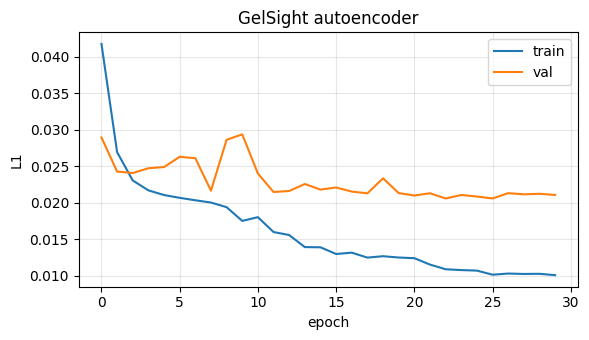

In [17]:
class GelSightEncoder(nn.Module):
    def __init__(self, in_ch=6, latent=128):
        super().__init__()
        self.enc = nn.Sequential(nn.Conv2d(in_ch, 32, 4, 2, 1), nn.GELU(), nn.Conv2d(32, 64, 4, 2, 1), nn.GELU(),
                                 nn.Conv2d(64, 128, 4, 2, 1), nn.GELU(), nn.AdaptiveAvgPool2d(1), nn.Flatten(),
                                 nn.Linear(128, latent))
        self.dec_fc = nn.Linear(latent, 128 * 8 * 8)
        self.dec = nn.Sequential(nn.ConvTranspose2d(128, 64, 4, 2, 1), nn.GELU(), nn.ConvTranspose2d(64, 32, 4, 2, 1), nn.GELU(),
                                 nn.ConvTranspose2d(32, in_ch, 4, 2, 1), nn.Sigmoid())
    def forward(self, x):
        z = self.enc(x); y = self.dec(self.dec_fc(z).view(-1, 128, 8, 8)); return y, z

ae = GelSightEncoder().to(DEVICE)
opt = torch.optim.AdamW(ae.parameters(), lr=1e-3, weight_decay=1e-5)
EPOCHS = 30; best = float("inf"); best_state = None; history = []
for ep in range(EPOCHS):
    ae.train(); tr = []
    for x, *_ in train_dl:
        x = x.to(DEVICE); opt.zero_grad(); y, _ = ae(x); loss = F.l1_loss(y, x); loss.backward()
        torch.nn.utils.clip_grad_norm_(ae.parameters(), 1.0); opt.step(); tr.append(loss.item())
    ae.eval(); va = []
    with torch.no_grad():
        for x, *_ in val_dl:
            x = x.to(DEVICE); y, _ = ae(x); va.append(F.l1_loss(y, x).item())
    v = float(np.mean(va)); history.append((float(np.mean(tr)), v))
    if v < best: best = v; best_state = {k: t.detach().cpu().clone() for k, t in ae.state_dict().items()}
    print(f"epoch {ep+1:02d}/{EPOCHS} train L1={np.mean(tr):.5f} val L1={v:.5f}")
ae.load_state_dict(best_state)

# ---- held-out metrics vs. a trivial baseline (predict the training-mean input)
with torch.no_grad():
    s = torch.zeros(6, IMAGE_SIZE, IMAGE_SIZE); n = 0
    for x, *_ in train_dl: s += x.sum(0); n += len(x)
    mean_x = (s / n).to(DEVICE)
    ae.eval(); l1, mse, l1b, mseb, lat = [], [], [], [], []
    for x, *_ in test_dl:
        x = x.to(DEVICE); y, z = ae(x)
        l1.append(F.l1_loss(y, x).item()); mse.append(F.mse_loss(y, x).item())
        b = mean_x.expand_as(x); l1b.append(F.l1_loss(b, x).item()); mseb.append(F.mse_loss(b, x).item())
        lat.append(z.cpu().numpy())
ae_metrics = pd.DataFrame({"test L1": [np.mean(l1), np.mean(l1b)], "test MSE": [np.mean(mse), np.mean(mseb)],
                           "PSNR dB": [-10 * np.log10(max(np.mean(mse), 1e-12)), -10 * np.log10(max(np.mean(mseb), 1e-12))]},
                          index=["autoencoder", "mean-image baseline"])
display(ae_metrics.round(5))
plt.figure(figsize=(6, 3.5)); h = np.array(history); plt.plot(h[:, 0], label="train"); plt.plot(h[:, 1], label="val")
plt.xlabel("epoch"); plt.ylabel("L1"); plt.title("GelSight autoencoder"); plt.legend(); plt.grid(alpha=.3); plt.tight_layout(); plt.show()

In [18]:
FEAT_DIM = 128
ACTIVATION = "relu"        # ASSUMPTION: not stored in the .pth
OFFSET_MODE = "displace"

def make_act(name):
    return {"relu": nn.ReLU, "gelu": nn.GELU, "silu": nn.SiLU, "softplus": lambda: nn.Softplus(beta=100)}[name]()

class GelSightFeatureAdapter(nn.Module):
    """Pretrained GelSight encoder (6-ch input) + projection to the SDF feature size."""
    def __init__(self, pretrained, out_dim=FEAT_DIM):
        super().__init__()
        self.encoder = pretrained.enc
        self.projection = nn.Sequential(nn.Linear(128, out_dim), nn.LayerNorm(out_dim), nn.GELU())
    def forward(self, x):
        return self.projection(self.encoder(x))

class OffsetNet(nn.Module):
    def __init__(self, hidden=128, act="relu"):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(2, hidden), make_act(act), nn.Linear(hidden, hidden), make_act(act), nn.Linear(hidden, 1))
    def forward(self, cond): return self.net(cond).squeeze(-1)

class DeformableTouchSDF(nn.Module):
    def __init__(self, tactile_encoder, feat_dim=FEAT_DIM, act=ACTIVATION, offset_mode=OFFSET_MODE):
        super().__init__()
        self.tactile_encoder = tactile_encoder; self.offset_mode = offset_mode
        self.base_mlp = nn.Sequential(nn.Linear(3 + feat_dim, 256), make_act(act), nn.Linear(256, 256), make_act(act), nn.Linear(256, 1))
        self.offset_net = OffsetNet(128, act)
        self.shape_emb = nn.Embedding(len(SHAPE_NAMES), feat_dim); nn.init.normal_(self.shape_emb.weight, std=0.5)
    def encode(self, x, sid=None):
        f = self.tactile_encoder(x); return f if sid is None else f + self.shape_emb(sid)
    def rest_sdf(self, pts, feat):                                   # Head 1
        return self.base_mlp(torch.cat([pts, feat[:, None, :].expand(-1, pts.shape[1], -1)], -1)).squeeze(-1)
    def offset(self, cond): return self.offset_net(cond)
    def deformed_sdf(self, pts, feat, cond):                         # Head 2
        off = self.offset(cond)
        if self.offset_mode == "displace":
            return self.rest_sdf(pts + off[:, None, None] * EZ, feat), off
        return self.rest_sdf(pts, feat) + off[:, None], off

CKPT_NAME = "deformable_touchsdf_250_epochs.pth"
cands = [Path("/content") / CKPT_NAME, Path(CKPT_NAME), Path("/mnt/user-data/attachments") / CKPT_NAME]
if Path("/mnt/user-data/attachments").exists(): cands += list(Path("/mnt/user-data/attachments").rglob("*" + CKPT_NAME))
CKPT_PATH = next((p for p in cands if p.exists()), None)
if CKPT_PATH is None:
    try:
        from google.colab import files
        print("Upload", CKPT_NAME); CKPT_PATH = Path(next(iter(files.upload())))
    except ImportError:
        raise FileNotFoundError(f"Put {CKPT_NAME} next to the notebook or in /content.")
print("Checkpoint:", CKPT_PATH)

def load_pretrained_heads(m, path):
    sd = torch.load(path, map_location="cpu")
    if isinstance(sd, dict) and "model_state_dict" in sd: sd = sd["model_state_dict"]
    heads = {k: v for k, v in sd.items() if k.startswith(("base_mlp.", "offset_net."))}
    missing, unexpected = m.load_state_dict(heads, strict=False)
    bad = [k for k in missing if not k.startswith(("tactile_encoder.", "shape_emb."))]
    assert not unexpected and not bad, (unexpected, bad)
    print("Loaded", len(heads), "head tensors from checkpoint (shapes matched).")

ae_sdf = copy.deepcopy(ae)
for p in list(ae_sdf.dec.parameters()) + list(ae_sdf.dec_fc.parameters()): p.requires_grad_(False)
sdf_model = DeformableTouchSDF(GelSightFeatureAdapter(ae_sdf)).to(DEVICE)
load_pretrained_heads(sdf_model, CKPT_PATH)

with torch.no_grad():
    xb, cb, cenb, db, sb = next(iter(test_dl)); xb, cb = xb.to(DEVICE), cb.to(DEVICE)
    feat = sdf_model.encode(xb); pts = torch.zeros(xb.shape[0], 5, 3, device=DEVICE)
    print("feature:", tuple(feat.shape), "| rest:", tuple(sdf_model.rest_sdf(pts, feat).shape),
          "| deformed:", tuple(sdf_model.deformed_sdf(pts, feat, cb)[0].shape))

Upload deformable_touchsdf_250_epochs.pth


Saving deformable_touchsdf_250_epochs_final.pth to deformable_touchsdf_250_epochs_final (6).pth
Checkpoint: deformable_touchsdf_250_epochs_final (6).pth
Loaded 12 head tensors from checkpoint (shapes matched).
feature: (64, 128) | rest: (64, 5) | deformed: (64, 5)


[A: encoder only] 01/10 train=0.5029 val=0.4102 (rest 0.0484 | deformed 0.0492 | offset 3.1265)
[A: encoder only] 02/10 train=0.4900 val=0.4098 (rest 0.0483 | deformed 0.0489 | offset 3.1265)
[A: encoder only] 03/10 train=0.4926 val=0.4095 (rest 0.0483 | deformed 0.0485 | offset 3.1265)
[A: encoder only] 04/10 train=0.4909 val=0.4094 (rest 0.0483 | deformed 0.0485 | offset 3.1265)
[A: encoder only] 05/10 train=0.4914 val=0.4095 (rest 0.0483 | deformed 0.0485 | offset 3.1265)
[A: encoder only] 06/10 train=0.4885 val=0.4093 (rest 0.0482 | deformed 0.0485 | offset 3.1265)
[A: encoder only] 07/10 train=0.4856 val=0.4093 (rest 0.0482 | deformed 0.0485 | offset 3.1265)
[A: encoder only] 08/10 train=0.4910 val=0.4091 (rest 0.0481 | deformed 0.0484 | offset 3.1265)
[A: encoder only] 09/10 train=0.4970 val=0.4093 (rest 0.0481 | deformed 0.0485 | offset 3.1265)
[A: encoder only] 10/10 train=0.4965 val=0.4090 (rest 0.0480 | deformed 0.0484 | offset 3.1265)
[B: full] 01/150 train=0.4738 val=0.3457

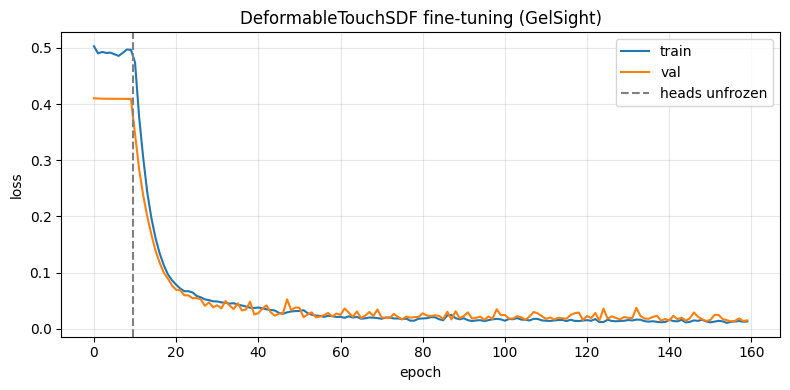

In [19]:
N_PTS = 2048; N_EIK = 256
EPOCHS_WARM = 10; EPOCHS_FULL = 150
LR_ENC_WARM, LR_ENC_FULL, LR_HEAD = 3e-4, 3e-4, 3e-4
W_OFF, W_EIK = 0.1, 0.01

def set_requires_grad(mod, flag):
    for p in mod.parameters(): p.requires_grad_(flag)

def compute_losses(xb, cb, cenb, db, sb, train, shuffle_feat=False, shuffle_cond=False):
    B = xb.shape[0]; c_rest = rest_center(cenb)
    pts = sample_points(c_rest, db, N_PTS, sb); gt_r, gt_d = gt_sdfs(pts, c_rest, db, sb)
    feat = sdf_model.encode(xb, sb); cb_used = cb
    if shuffle_feat: feat = feat[torch.randperm(B, device=feat.device)]
    if shuffle_cond: cb_used = cb[torch.randperm(B, device=cb.device)]
    pr = sdf_model.rest_sdf(pts, feat); pd_, off = sdf_model.deformed_sdf(pts, feat, cb_used)
    cl = lambda t: t.clamp(-SDF_CLAMP, SDF_CLAMP)
    l_r = F.l1_loss(cl(pr), cl(gt_r)); l_d = F.l1_loss(cl(pd_), cl(gt_d)); l_o = F.l1_loss(off, db)
    loss = l_r + l_d + W_OFF * l_o; l_e = torch.zeros((), device=xb.device)
    if train:
        ep = (LO_T + (HI_T - LO_T) * torch.rand(B, N_EIK, 3, device=xb.device)).requires_grad_(True)
        gr = torch.autograd.grad(sdf_model.rest_sdf(ep, feat).sum(), ep, create_graph=True)[0]
        l_e = ((gr.norm(dim=-1) - 1) ** 2).mean(); loss = loss + W_EIK * l_e
    return loss, {"rest": l_r.item(), "deformed": l_d.item(), "offset": l_o.item(), "eik": l_e.item()}

def run_epoch(loader, opt=None):
    train = opt is not None; sdf_model.train(train); agg, losses = defaultdict(list), []
    for xb, cb, cenb, db, sb in loader:
        xb, cb, cenb, db, sb = xb.to(DEVICE), cb.to(DEVICE), cenb.to(DEVICE), db.to(DEVICE), sb.to(DEVICE)
        with torch.set_grad_enabled(train):
            loss, parts = compute_losses(xb, cb, cenb, db, sb, train)
        if train:
            opt.zero_grad(set_to_none=True); loss.backward()
            torch.nn.utils.clip_grad_norm_([p for g_ in opt.param_groups for p in g_["params"]], 1.0); opt.step()
        losses.append(loss.item())
        for k, v in parts.items(): agg[k].append(v)
    return float(np.mean(losses)), {k: float(np.mean(v)) for k, v in agg.items()}

sdf_history, best_val, best_sdf_state = [], float("inf"), None
def fit(n_epochs, opt, tag):
    global best_val, best_sdf_state
    for ep in range(n_epochs):
        tr, _ = run_epoch(train_dl, opt); va, vap = run_epoch(val_dl)
        sdf_history.append({"phase": tag, "train": tr, "val": va, **{f"val_{k}": v for k, v in vap.items()}})
        if va < best_val:
            best_val = va; best_sdf_state = {k: v.detach().cpu().clone() for k, v in sdf_model.state_dict().items()}
        print(f"[{tag}] {ep+1:02d}/{n_epochs} train={tr:.4f} val={va:.4f} (rest {vap['rest']:.4f} | deformed {vap['deformed']:.4f} | offset {vap['offset']:.4f})")

set_requires_grad(sdf_model.base_mlp, False); set_requires_grad(sdf_model.offset_net, False)
enc_params = [p for p in sdf_model.tactile_encoder.parameters() if p.requires_grad] + list(sdf_model.shape_emb.parameters())
fit(EPOCHS_WARM, torch.optim.AdamW(enc_params, lr=LR_ENC_WARM, weight_decay=1e-4), "A: encoder only")
set_requires_grad(sdf_model.base_mlp, True); set_requires_grad(sdf_model.offset_net, True)
head_params = list(sdf_model.base_mlp.parameters()) + list(sdf_model.offset_net.parameters())
fit(EPOCHS_FULL, torch.optim.AdamW([{"params": enc_params, "lr": LR_ENC_FULL}, {"params": head_params, "lr": LR_HEAD}], weight_decay=1e-4), "B: full")
sdf_model.load_state_dict(best_sdf_state)

sdf_hist_df = pd.DataFrame(sdf_history)
plt.figure(figsize=(8, 4)); plt.plot(sdf_hist_df["train"].values, label="train"); plt.plot(sdf_hist_df["val"].values, label="val")
plt.axvline(EPOCHS_WARM - 0.5, color="gray", ls="--", label="heads unfrozen")
plt.xlabel("epoch"); plt.ylabel("loss"); plt.title("DeformableTouchSDF fine-tuning (GelSight)"); plt.legend(); plt.grid(alpha=.3); plt.tight_layout(); plt.show()

In [20]:
@torch.no_grad()
def evaluate(loader, shuffle_feat=False, shuffle_cond=False, seed=0):
    sdf_model.eval(); torch.manual_seed(seed); agg = defaultdict(list)
    for xb, cb, cenb, db, sb in loader:
        xb, cb, cenb, db, sb = xb.to(DEVICE), cb.to(DEVICE), cenb.to(DEVICE), db.to(DEVICE), sb.to(DEVICE)
        _, parts = compute_losses(xb, cb, cenb, db, sb, False, shuffle_feat, shuffle_cond)
        for k in ("rest", "deformed", "offset"): agg[k].append(parts[k])
    return {k: float(np.mean(v)) for k, v in agg.items()}

eval_df = pd.DataFrame({
    "as measured": evaluate(test_dl),
    "tactile feature shuffled": evaluate(test_dl, shuffle_feat=True),
    "force/stiffness shuffled": evaluate(test_dl, shuffle_cond=True),
}).T.rename(columns={"rest": "rest SDF L1", "deformed": "deformed SDF L1", "offset": "offset MAE"})
display(eval_df.round(4))

,rest SDF L1,deformed SDF L1,offset MAE
as measured,0.0051,0.0053,0.0020
tactile feature shuffled,0.0102,0.0103,0.0020
force/stiffness shuffled,0.0051,0.0083,0.0281


Mesh validation on 39 frames, 13 per shape (normalized units; 1 unit = 20 cm, sphere radius = 0.25) - mean per shape:


,surface found (rest),surface found (deformed),rest surface err,deformed surface err,rest centroid err,deformed centroid err,offset abs err
shape,,,,,,,
sphere,1.0,1.0,0.0068,0.0070,0.0086,0.0084,0.0021
cylinder,1.0,1.0,0.0129,0.0130,0.0030,0.0028,0.0018
foam_ellipsoid,1.0,1.0,0.0061,0.0064,0.0044,0.0040,0.0021


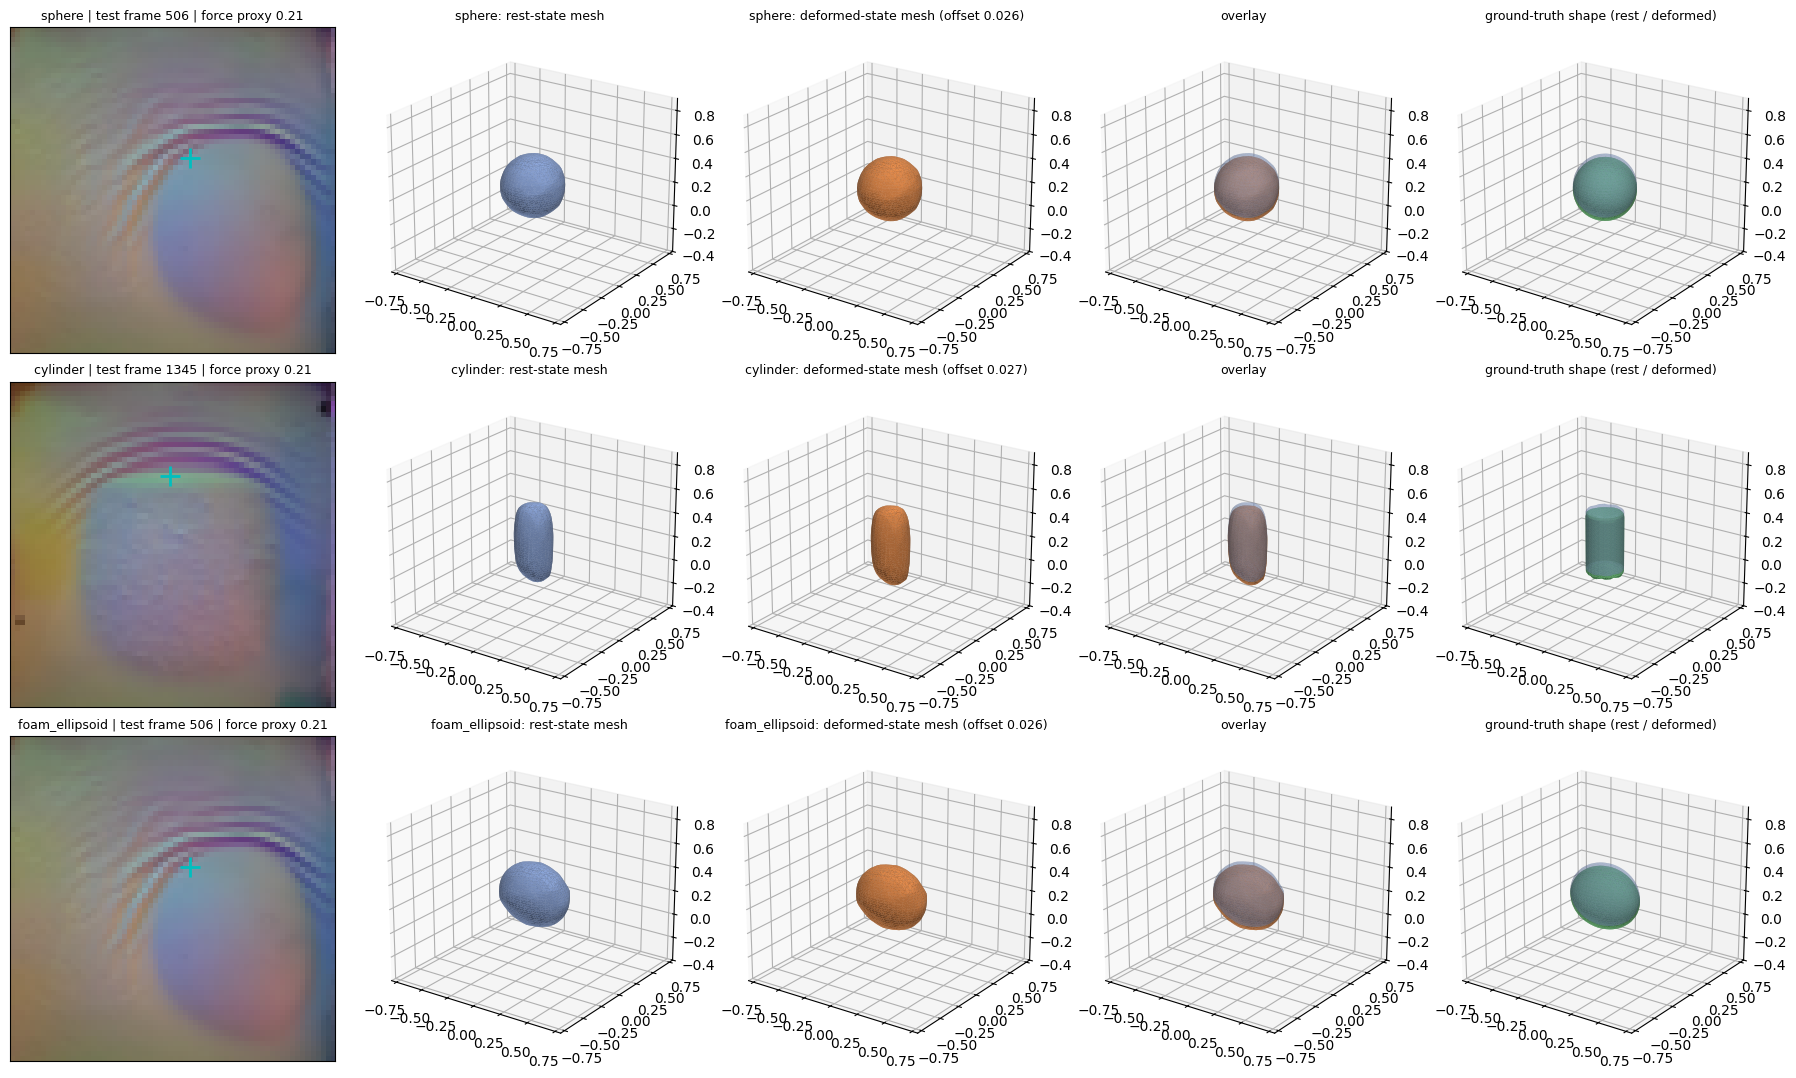

Saved meshes: ['asymmetric_frame02379_deformed.obj', 'asymmetric_frame02379_gt_deformed.obj', 'asymmetric_frame02379_gt_rest.obj', 'asymmetric_frame02379_rest.obj', 'cylinder_frame00955_deformed.obj', 'cylinder_frame00955_gt_deformed.obj', 'cylinder_frame00955_gt_rest.obj', 'cylinder_frame00955_rest.obj', 'cylinder_frame01345_deformed.obj', 'cylinder_frame01345_gt_deformed.obj', 'cylinder_frame01345_gt_rest.obj', 'cylinder_frame01345_rest.obj', 'foam_ellipsoid_frame00506_deformed.obj', 'foam_ellipsoid_frame00506_gt_deformed.obj', 'foam_ellipsoid_frame00506_gt_rest.obj', 'foam_ellipsoid_frame00506_rest.obj', 'foam_ellipsoid_frame01347_deformed.obj', 'foam_ellipsoid_frame01347_gt_deformed.obj', 'foam_ellipsoid_frame01347_gt_rest.obj', 'foam_ellipsoid_frame01347_rest.obj', 'sphere_frame00506_deformed.obj', 'sphere_frame00506_gt_deformed.obj', 'sphere_frame00506_gt_rest.obj', 'sphere_frame00506_rest.obj', 'sphere_frame00520_deformed.obj', 'sphere_frame00520_gt_deformed.obj', 'sphere_frame0

In [21]:
from skimage.measure import marching_cubes
from mpl_toolkits.mplot3d.art3d import Poly3DCollection

MESH_RES = 64; EVAL_RES = 48; CHUNK = 32768; N_MESH_EVAL = 40
OUTPUT_DIR = Path("outputs_gelsight"); MESH_DIR = OUTPUT_DIR / "meshes"; MESH_DIR.mkdir(parents=True, exist_ok=True)

@torch.no_grad()
def eval_volume(fn, res):
    axes = [np.linspace(BOUNDS_LO[i], BOUNDS_HI[i], res) for i in range(3)]
    G = np.stack(np.meshgrid(*axes, indexing="ij"), -1).reshape(-1, 3).astype(np.float32); out = []
    for i in range(0, len(G), CHUNK):
        out.append(fn(torch.from_numpy(G[i:i + CHUNK]).to(DEVICE)[None])[0].float().cpu().numpy())
    return np.concatenate(out).reshape(res, res, res), axes

def volume_to_mesh(vol, axes):
    if not (vol.min() < 0.0 < vol.max()): return None
    v, f, _, _ = marching_cubes(vol, level=0.0, spacing=tuple(float(a[1] - a[0]) for a in axes))
    return (v + np.array([a[0] for a in axes])).astype(np.float32), f

def save_obj(mesh, path):
    v, f = mesh
    with open(path, "w") as fh:
        fh.write("# generated by GelSight DeformableTouchSDF notebook\n")
        for p in v: fh.write(f"v {p[0]:.6f} {p[1]:.6f} {p[2]:.6f}\n")
        for t in f + 1: fh.write(f"f {t[0]} {t[1]} {t[2]}\n")

@torch.no_grad()
def reconstruct_normalized(x6, cond, res=MESH_RES, sid=None):
    """x6 [1,6,H,W] tactile input, cond [1,2] normalized (force proxy, stiffness), sid = shape id (int, as in training)."""
    sdf_model.eval(); sid_t = None if sid is None else torch.tensor([sid], device=DEVICE)
    feat = sdf_model.encode(x6.to(DEVICE), sid_t); cond = cond.to(DEVICE)
    rv, axes = eval_volume(lambda p: sdf_model.rest_sdf(p, feat), res)
    dv, _ = eval_volume(lambda p: sdf_model.deformed_sdf(p, feat, cond)[0], res)
    return volume_to_mesh(rv, axes), volume_to_mesh(dv, axes), float(sdf_model.offset(cond))

def reconstruct_from_image(rgb_image, reference_rgb, force_proxy, stiffness=1.0, res=MESH_RES, sid=None):
    """End-to-end: a raw GelSight frame + its no-contact reference + force proxy; meshes are in the contact-centred frame."""
    img = torch.from_numpy(prep_rgb(rgb_image)); ref = torch.from_numpy(prep_rgb(reference_rgb))
    cond = torch.tensor([[np.clip(force_proxy / F_SCALE, 0, 2), np.clip(stiffness / K_REF, 0.25, 4)]], dtype=torch.float32)
    return reconstruct_normalized(make_x6(img, ref)[None], cond, res, sid)

@torch.no_grad()
def mesh_stats(mesh, c, cen_xy, sid):
    """Mean |true-shape SDF| at the mesh vertices (= surface error) and xy-centroid error."""
    if mesh is None: return np.nan, np.nan
    v = mesh[0]; vt = torch.from_numpy(v)[None].to(DEVICE); ct = torch.as_tensor(c, dtype=torch.float32, device=DEVICE)[None]
    err = shape_sdf(vt, ct, torch.tensor([sid], device=DEVICE))[0].abs().mean().item()
    return err, float(np.linalg.norm(v[:, :2].mean(0) - cen_xy))

@torch.no_grad()
def gt_mesh(c, sid, res=MESH_RES):
    """Ground-truth (pseudo-GT) mesh of shape `sid` centred at c."""
    ct = torch.as_tensor(c, dtype=torch.float32, device=DEVICE)[None]; st = torch.tensor([sid], device=DEVICE)
    vol, axes = eval_volume(lambda p: shape_sdf(p, ct, st), res)
    return volume_to_mesh(vol, axes)

def frames_for_shape(sid):
    """Held-out test frames used for this shape; falls back to train/val frames if the test split has none."""
    m = test_sh == sid
    if m.any(): return test_fr[m], "test"
    print(f"WARNING: no test frames for '{SHAPE_NAMES[sid]}' - using train/val frames instead")
    return all_fr[all_sh == sid], "train/val"

# ---- quantitative mesh validation on random held-out frames, stratified over the shapes
recs = []
for sid, nm in enumerate(SHAPE_NAMES):
    cand, split = frames_for_shape(sid)
    for j in np.random.default_rng(0).choice(cand, min(N_MESH_EVAL // len(SHAPE_NAMES), len(cand)), replace=False):
        x6 = make_x6(Xt[j], REFt[fid_t[j]])[None]; cb = cond_t[j][None]
        rm, dm, off = reconstruct_normalized(x6, cb, EVAL_RES, sid)
        c_rest = np.array([0., 0., SPHERE_R]); c_def = c_rest - np.array([0, 0, delta_all[j]])
        re, rc = mesh_stats(rm, c_rest, np.zeros(2), sid); de, dc = mesh_stats(dm, c_def, np.zeros(2), sid)
        recs.append({"shape": nm, "split": split, "surface found (rest)": rm is not None, "surface found (deformed)": dm is not None,
                     "rest surface err": re, "deformed surface err": de, "rest centroid err": rc, "deformed centroid err": dc,
                     "offset abs err": abs(off - delta_all[j])})
mesh_val = pd.DataFrame(recs)
summary = mesh_val.drop(columns="split").groupby("shape").mean(numeric_only=True).reindex(SHAPE_NAMES)
print(f"Mesh validation on {len(mesh_val)} frames, {N_MESH_EVAL // len(SHAPE_NAMES)} per shape (normalized units; 1 unit = 20 cm, sphere radius = {SPHERE_R}) - mean per shape:")
display(summary.round(4))

# ---- qualitative figure: one frame per shape (median touch depth), reconstructed vs. ground-truth shape
def shaded_poly(mesh, color):
    v, f = mesh; tri = v[f]; n = np.cross(tri[:, 1] - tri[:, 0], tri[:, 2] - tri[:, 0]); n /= (np.linalg.norm(n, axis=1, keepdims=True) + 1e-9)
    shade = 0.45 + 0.55 * np.abs(n @ np.array([0.4, -0.3, 0.86]))
    return Poly3DCollection(tri, facecolors=np.clip(np.outer(shade, color), 0, 1), edgecolor="none")

def draw_mesh(ax, items, title):
    for mesh, color, alpha in items:
        if mesh is not None:
            pc = shaded_poly(mesh, color); pc.set_alpha(alpha); ax.add_collection3d(pc)
    ax.set_xlim(-.8, .8); ax.set_ylim(-.8, .8); ax.set_zlim(BOUNDS_LO[2], BOUNDS_HI[2])
    ax.set_box_aspect((1.6, 1.6, BOUNDS_HI[2] - BOUNDS_LO[2])); ax.set_title(title, fontsize=9); ax.view_init(22, -55)

NCOL = 5
fig = plt.figure(figsize=(18, 3.6 * len(SHAPE_NAMES)))
for r, nm in enumerate(SHAPE_NAMES):
    cand, split = frames_for_shape(r); j = int(cand[np.argsort(delta_all[cand])[len(cand) // 2]])
    x6 = make_x6(Xt[j], REFt[fid_t[j]])[None]; cb = cond_t[j][None]
    rm, dm, off = reconstruct_normalized(x6, cb, MESH_RES, r)
    c_rest = np.array([0., 0., SPHERE_R]); c_def = c_rest - np.array([0, 0, delta_all[j]])
    gr, gd = gt_mesh(c_rest, r), gt_mesh(c_def, r)
    for name, m in (("rest", rm), ("deformed", dm), ("gt_rest", gr), ("gt_deformed", gd)):
        if m is not None: save_obj(m, MESH_DIR / f"{nm}_frame{j:05d}_{name}.obj")
    ax = fig.add_subplot(len(SHAPE_NAMES), NCOL, NCOL * r + 1)
    ax.imshow(Xt[j].permute(1, 2, 0).numpy(), extent=[-.5, .5, .5, -.5]); ax.plot(*cen[j], "c+", ms=14, mew=2)
    ax.set_title(f"{nm} | {split} frame {j} | force proxy {cond_all[j,0]:.2f}", fontsize=9); ax.set_xticks([]); ax.set_yticks([])
    draw_mesh(fig.add_subplot(len(SHAPE_NAMES), NCOL, NCOL * r + 2, projection="3d"), [(rm, np.array([.55, .65, .85]), 1)], f"{nm}: rest-state mesh")
    draw_mesh(fig.add_subplot(len(SHAPE_NAMES), NCOL, NCOL * r + 3, projection="3d"), [(dm, np.array([.9, .55, .3]), 1)], f"{nm}: deformed-state mesh (offset {off:.3f})")
    draw_mesh(fig.add_subplot(len(SHAPE_NAMES), NCOL, NCOL * r + 4, projection="3d"), [(rm, np.array([.55, .65, .85]), .35), (dm, np.array([.9, .55, .3]), .9)], "overlay")
    draw_mesh(fig.add_subplot(len(SHAPE_NAMES), NCOL, NCOL * r + 5, projection="3d"), [(gr, np.array([.55, .65, .85]), .35), (gd, np.array([.4, .75, .45]), .9)], "ground-truth shape (rest / deformed)")
plt.tight_layout(); plt.savefig(OUTPUT_DIR / "reconstructions.png", dpi=130); plt.show()
print("Saved meshes:", sorted(p.name for p in MESH_DIR.glob("*.obj")))

In [25]:
N_CD_PTS = 5000; N_CD_FRAMES = 15; CM_PER_UNIT = 20.0

def sample_mesh(mesh, n, rng):
    """Area-weighted random points on a triangle mesh."""
    v, f = mesh; tri = v[f]
    area = 0.5 * np.linalg.norm(np.cross(tri[:, 1] - tri[:, 0], tri[:, 2] - tri[:, 0]), axis=1)
    k = rng.choice(len(f), n, p=area / area.sum()); u, w = rng.random((n, 1)), rng.random((n, 1))
    flip = u + w > 1; u[flip], w[flip] = 1 - u[flip], 1 - w[flip]; t = tri[k]
    return (t[:, 0] + u * (t[:, 1] - t[:, 0]) + w * (t[:, 2] - t[:, 0])).astype(np.float32)

@torch.no_grad()
def chamfer(a, b, rng):
    """Symmetric Chamfer distance = 0.5 * (mean NN dist a->b + mean NN dist b->a); NaN if a surface is missing."""
    if a is None or b is None: return np.nan
    A = torch.from_numpy(sample_mesh(a, N_CD_PTS, rng)).to(DEVICE); B = torch.from_numpy(sample_mesh(b, N_CD_PTS, rng)).to(DEVICE)
    d = torch.cdist(A, B); return 0.5 * (d.min(1).values.mean() + d.min(0).values.mean()).item()

rng_cd = np.random.default_rng(0); rows = []
for sid, nm in enumerate(SHAPE_NAMES):
    cand, split = frames_for_shape(sid)
    for j in np.random.default_rng(1).choice(cand, min(N_CD_FRAMES, len(cand)), replace=False):
        x6 = make_x6(Xt[j], REFt[fid_t[j]])[None]; cb = cond_t[j][None]
        rm, dm, _ = reconstruct_normalized(x6, cb, MESH_RES, sid)
        gd = gt_mesh(np.array([0., 0., SPHERE_R - delta_all[j]]), sid)          # ground-truth shape in contact (deformed) pose
        rows.append({"shape": nm, "TouchSDF": chamfer(rm, gd, rng_cd), "Deformable TouchSDF": chamfer(dm, gd, rng_cd)})
cd = pd.DataFrame(rows)
tab = cd.groupby("shape").agg(frames=("TouchSDF", "size"), TouchSDF=("TouchSDF", "mean"),
                              DeformableTouchSDF=("Deformable TouchSDF", "mean")).reindex(SHAPE_NAMES)
tab = tab.rename(columns={"TouchSDF": "TouchSDF CD", "DeformableTouchSDF": "Deformable TouchSDF CD"})
tab["CD reduction (%)"] = 100 * (tab["TouchSDF CD"] - tab["Deformable TouchSDF CD"]) / tab["TouchSDF CD"]
tab.loc["mean"] = tab.mean(); tab.loc["mean", "frames"] = tab["frames"].iloc[:-1].sum()
print("Chamfer distance to the ground-truth deformed shape (normalized units; 1 unit = 20 cm). Lower is better.")
display(tab.round(4)); tab.to_csv(OUTPUT_DIR / "chamfer_touchsdf_vs_deformable.csv")

Chamfer distance to the ground-truth deformed shape (normalized units; 1 unit = 20 cm). Lower is better.


,frames,TouchSDF CD,Deformable TouchSDF CD,CD reduction (%)
shape,,,,
sphere,15.0,0.0196,0.0102,48.1182
cylinder,15.0,0.0179,0.0149,16.8845
foam_ellipsoid,15.0,0.0180,0.0097,46.0340
mean,45.0,0.0185,0.0116,37.0122


In [26]:
torch.save({
    "model_state_dict": sdf_model.state_dict(),
    "config": {"feat_dim": FEAT_DIM, "activation": ACTIVATION, "offset_mode": OFFSET_MODE, "image_size": IMAGE_SIZE,
               "input_channels": 6, "bounds_lo": BOUNDS_LO, "bounds_hi": BOUNDS_HI, "sphere_r": SPHERE_R,
               "shape_names": SHAPE_NAMES, "shapes_by_file": SHAPES_BY_FILE, "cyl_r": CYL_R, "cyl_half_h": CYL_HALF_H,
               "ell_axes": ELL_AXES},
    "normalization": {"F_SCALE": F_SCALE, "K_REF": K_REF},
    "note": "GelSight -> DeformableTouchSDF. Force is an image-deviation proxy; geometry supervision is pseudo-GT."
}, OUTPUT_DIR / "gelsight_deformable_touchsdf.pth")
np.savez_compressed(OUTPUT_DIR / "gelsight_references.npz", refs=REF, files=uniq_files)
torch.save(ae.state_dict(), OUTPUT_DIR / "gelsight_autoencoder.pth")
sdf_hist_df.to_csv(OUTPUT_DIR / "sdf_training_history.csv", index=False)
eval_df.to_csv(OUTPUT_DIR / "sdf_test_metrics.csv"); ae_metrics.to_csv(OUTPUT_DIR / "autoencoder_test_metrics.csv")
mesh_val.to_csv(OUTPUT_DIR / "mesh_validation.csv", index=False)
shutil.make_archive("gelsight_touchsdf_outputs", "zip", OUTPUT_DIR)
print("Wrote", os.path.abspath("gelsight_touchsdf_outputs.zip"))
try:
    from google.colab import files as colab_files
    colab_files.download("gelsight_touchsdf_outputs.zip")
except ImportError:
    pass

Wrote /content/gelsight_touchsdf_outputs.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>